# A design loop: finding the best structure with few calculations

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/22_a_design_loop.ipynb)

Every notebook so far asks how well a model predicts. A design study asks something else. There are
thousands of candidate structures, and each calculation (or each synthesis) is expensive. Can a
model find the best candidate with a small budget of calculations?

The answer is a **design loop**. Start from a few computed candidates. Fit a model on them. Let
a **rule** pick the next candidate to compute from the model's predictions. Compute it, add it to
the model, and repeat until the budget is spent. `cmfqsar/prototypes.py` holds the three parts:
a generator of candidates over a **prototype** cell, a test for which candidates are the same
structure, and the loop itself (`design_loop`).

The rules used here:

- **random**: pick any candidate not yet computed. It needs no model, and it is the baseline that
  every other rule has to beat.
- **greedy**: pick the candidate with the best predicted value.
- **ucb**: pick the best predicted value after one standard deviation of the prediction is taken
  in its favour (the confidence bound), so that uncertain candidates get a chance.

The judge is the **rank** of the best candidate the loop found in the whole pool, where 1 is the
best candidate there is, and how many calls it took to reach the best 1 % of the pool. The pools
are retrospective: every value is known in advance, and the loop may only read a value it has
paid a call for. The notebook asks four questions.

1. How large is a design space, and when are two candidates the same structure?
2. Does the loop find a better perovskite than its start set within 100 calls?
3. Does it need the fields to do that? The reference, new in this notebook, is the same loop with
   a model that needs no field: the names of the elements, or the counts of the defects.
4. Why did the field model fail on one pool of defects, and what repairs it?

The first run downloads the Matbench perovskite set (4 MB) and, if the defect notebook has not
been run, the 2DMD defect set (5 MB). Running time: about two minutes.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## The design space

A **prototype** is one cell with **site classes**: groups of sites that take an element from a
list. The five-atom cubic perovskite ABX3 has an A site and a B site. With the 52 A elements and
52 B elements of `matbench_perovskites`, it allows 52 x 52 = 2,704 oxides. `candidate_at` turns
one index into one structure, so a space of millions of candidates never has to be listed.

In [2]:
import json
import os
import sys
import time

sys.path.insert(0, "benchmarks")

import matplotlib.pyplot as plt
import numpy as np
from ase.build import bulk

import run_prototypes as R
from cmfqsar import prototypes as P

space = json.load(open(os.path.join(R.RESULTS, "space.json")))
a_list, b_list = space["perovskites"]["a_list"], space["perovskites"]["b_list"]
proto = P.Prototype.by_symbol(P.cubic_perovskite(3.9), {"Sr": a_list, "Ti": b_list})
print("ABO3 with %d A and %d B elements: %d candidates" % (len(a_list), len(b_list), proto.n_candidates))
for i in (0, 1234, proto.n_candidates - 1):
    print("   candidate %4d: %s" % (i, proto.candidate_at(i).formula))

host = bulk("Cu", "fcc", a=3.6, cubic=True) * (2, 2, 1)
print()
print("Au atoms placed on the %d sites of an fcc copper cell:" % len(host))
for count in (1, 2, 3):
    proto_d = P.Prototype(host, (P.SiteClass("Cu", tuple(range(len(host))), ("Au",), count=count),))
    placements = P.candidates(proto_d)
    kept, dropped = P.unique(proto_d, placements)
    print("   %d Au: %4d placements, %2d distinct structures after the symmetry of the cell" % (count, len(placements), len(kept)))

ABO3 with 52 A and 52 B elements: 2704 candidates
   candidate    0: Ag2O3
   candidate 1234: LiO3Sb
   candidate 2703: O3Zr2

Au atoms placed on the 16 sites of an fcc copper cell:
   1 Au:   16 placements,  1 distinct structures after the symmetry of the cell
   2 Au:  120 placements,  5 distinct structures after the symmetry of the cell


   3 Au:  560 placements, 10 distinct structures after the symmetry of the cell


Most placements of a substituent are the same structure seen from another place in the cell. Of 560
ways to put three Au atoms on 16 sites, only 10 are different structures. `P.unique` removes the
others with the symmetry operations of the prototype, so the loop never pays twice for one
structure.

## The loop on a published pool of perovskites

The pool is 4,000 cells of `matbench_perovskites` with their computed formation energy (eV per
atom). These cells are ABX3 with X = O, N, F or S, often mixed. The target is minimised: a lower
formation energy is a more stable compound.

The cell runs three loops from the same 10 start sets of 25 computed cells, each with a budget of
100 calls:

- **random** choice;
- **greedy on the fields**: kernel ridge on the two-point field autocorrelation of the cells
  (the descriptor of the crystal notebooks), with the ridge chosen by the evidence at every step;
- **greedy on the names**: the same loop, but its model is a linear kernel on the **names of the
  elements**: one column for each element on the A site, one for each element on the B site, and
  the number of X sites each anion takes. A chemist writes these columns down without computing
  anything.

The field rows of the 4,000 cells are computed once (about 20 seconds) and kept in
`benchmarks/cache/prototypes`.

4000 cells, formation energy -0.260 to +4.960 eV per atom; the line of the best 1 %: +0.160
start sets that already hold a cell at or below the line: 5 of 10
the names model has 108 columns


three loops x 10 start sets in 52 s

loop                     median rank   reached the best 1 %   median calls to reach it
random                       27 of 4000               3/10                     50
greedy on the fields         15 of 4000               6/10                     32
greedy on the names           1 of 4000              10/10                      4


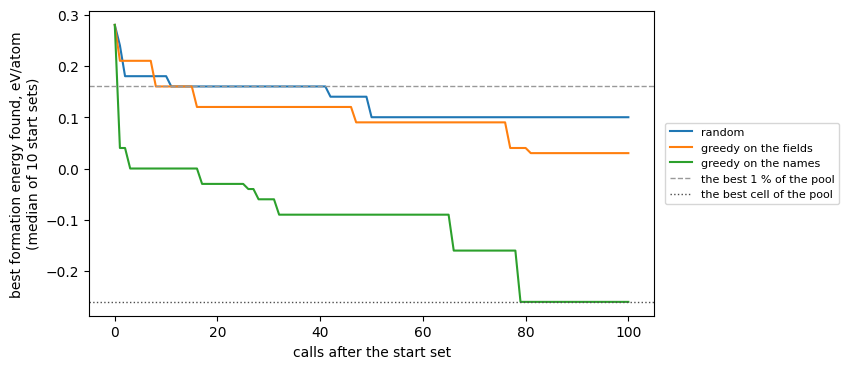

In [3]:
pool, y, table = R.pool_of("perovskites", R.POOL)
K_fields = R.kernel_for("perovskites", "two-point", table, R.POOL)
X_names, y_names, columns = R.element_name_columns("perovskites", R.POOL)
assert np.allclose(y, y_names)
K_names = R.linear_kernel(X_names)
starts = R.starts_for(len(y), 25, R.SEEDS)
cut = np.percentile(y, 1.0)                     # the best 1 % of the pool
print("%d cells, formation energy %+.3f to %+.3f eV per atom; the line of the best 1 %%: %+.3f" % (len(y), y.min(), y.max(), cut))
print("start sets that already hold a cell at or below the line: %d of %d" % (sum(1 for s in starts if y[s].min() <= cut), len(starts)))
print("the names model has %d columns" % X_names.shape[1])


def run(K, rule):
    curves, ranks, reach = [], [], []
    for seed, start in enumerate(starts):
        rec = P.design_loop(pool, P.LookupOracle(y), start=start, budget=R.BUDGET, kernel=K, rule=rule,
                            beta=R.BETA, lams=R.LAMS, maximise=False, seed=seed)
        curves.append([rec["start_best"]] + [s["best"] for s in rec["steps"]])
        ranks.append(int(np.sum(y < rec["best"])) + 1)
        reach.append(P.first_better(rec, cut))      # the first call below the 1 % line, or None
    return np.array(curves), ranks, reach


t0 = time.time()
live = {"random": run(K_names, "random"), "greedy on the fields": run(K_fields, "greedy"),
        "greedy on the names": run(K_names, "greedy")}
print("three loops x 10 start sets in %.0f s" % (time.time() - t0))
print()
print("%-22s %13s %22s %26s" % ("loop", "median rank", "reached the best 1 %", "median calls to reach it"))
for name, (curves, ranks, reach) in live.items():
    reach = [r for r in reach if r is not None]
    print("%-22s %8.0f of %d %15d/10 %22s" % (name, np.median(ranks), len(y), len(reach), "%.0f" % np.median(reach) if reach else "--"))

fig, ax = plt.subplots(figsize=(8.6, 3.8))
for name, (curves, _r, _c) in live.items():
    ax.plot(np.median(curves, axis=0), label=name)
ax.axhline(cut, color="0.6", linestyle="--", linewidth=1, label="the best 1 % of the pool")
ax.axhline(y.min(), color="0.3", linestyle=":", linewidth=1, label="the best cell of the pool")
ax.set_xlabel("calls after the start set")
ax.set_ylabel("best formation energy found, eV/atom\n(median of 10 start sets)")
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.show()

A run counts as having reached the best 1 % only when one of its own calls finds a cell below the
line. Many cells sit exactly on the line (+0.16 eV per atom), and five of the ten start sets
already hold one, so the line is strict.

Random choice ends at a median rank of 27 of 4,000 and crosses the line in 3 of 10 runs, after a
median of 50 calls. Greedy on the fields does better: median rank 15, the line crossed in 6 of 10
runs, after 32 calls. Greedy on the names finds the best cell of the pool (median rank 1), and it
crosses the line in 10 of 10 runs after a median of 4 calls. The figure shows the median of the
best value found after each call. The names model drops below the line in its first calls.

These numbers are the stored ones: the live run repeats the stage `loop` of the benchmark exactly.
So on this pool the loop does not need the fields. The formation energy of these cells depends
mostly on which elements they hold, and a model that reads only the names learns that from 25
cells.

## Every pool, from the stored runs

`run_prototypes.py` runs the loop on three pools: the perovskites, and the 2DMD defect series of
MoS2 and of WSe2 (2,000 arrangements of one to three point defects on one host lattice each). It
runs it from start sets of 25 and of 100 cells. Its field model is the **three-body** kernel of the
whole cell (plan item M10). The stage `--stage cheap` reruns the same loops, with the same start
sets, with the models that need no field:

- **element names** for the perovskites, as above;
- **defect counts** for the defect pools: how many defects of each kind the cell holds (four
  columns);
- **pair expansion**: those counts and the pairs of kinds at each distance up to 12 Å, the
  reference of the defect notebook.

For the defect pools the same stage also runs the field kernel of the defect notebook, the
**difference fields**, which is explained below. Besides what each loop found, the table shows
**the place of the best candidate**: where the model, fitted on the start set alone, puts the best
candidate of the pool in its own order. A greedy rule acts on that order.

In [4]:
cheap = json.load(open(os.path.join(R.RESULTS, "cheap.json")))
loops = json.load(open(os.path.join(R.RESULTS, "loop.json")))
loops.update(json.load(open(os.path.join(R.RESULTS, "defects.json"))))
ranking = json.load(open(os.path.join(R.RESULTS, "ranking.json")))
print("%-12s %5s %-22s %13s %15s %13s %12s" % ("pool", "start", "model (greedy rule)", "median rank", "best 1 % in", "median calls", "place of best"))
for name, n in (("perovskites", 4000), ("MoS2", 2000), ("WSe2", 2000)):
    for size in (25, 100):
        rows = [("random choice", loops["%s | three-body | %d | start %d" % (name, n, size)]["random"], None),
                ("three-body fields", loops["%s | three-body | %d | start %d" % (name, n, size)]["greedy"],
                 ranking["%s | three-body | %d | start %d" % (name, n, size)]["place_median"])]
        for model in R.CHEAP_MODELS["perovskites" if name == "perovskites" else "defects"]:
            r = cheap["%s | %s | %d | start %d" % (name, model, n, size)]
            rows.append((model, r["greedy"], r["ordering"]["place_median"]))
        for model, v, place in rows:
            calls = "%.0f" % v["reached_top_median"] if v["reached_top_median"] is not None else "--"
            print("%-12s %5d %-22s %8.0f of %d %12d/10 %13s %12s" % (name, size, model, v["rank_median"], n, v["reached_top_runs"], calls,
                                                                  "" if place is None else "%.0f" % place))
        print()

pool         start model (greedy rule)      median rank     best 1 % in  median calls place of best
perovskites     25 random choice                27 of 4000            3/10            50             
perovskites     25 three-body fields             1 of 4000            8/10            16          846
perovskites     25 element names                 1 of 4000           10/10             4          656

perovskites    100 random choice                14 of 4000            6/10            37             
perovskites    100 three-body fields             1 of 4000            8/10             8          227
perovskites    100 element names                 1 of 4000           10/10             2          144

MoS2            25 random choice                10 of 2000            7/10            46             
MoS2            25 three-body fields            37 of 2000            0/10            --          929
MoS2            25 defect counts                18 of 2000            8/10        

The picture shows the last column of every pool at a start set of 25: how many calls each model
needed, in the median, before one of its own calls found a cell of the best 1 %. A missing bar
means the model never reached it within the budget.

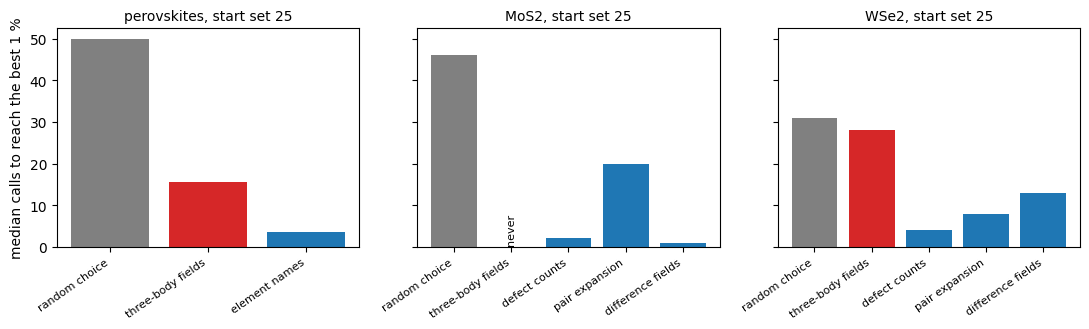

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, (name, n) in zip(axes, (("perovskites", 4000), ("MoS2", 2000), ("WSe2", 2000))):
    key = "%s | three-body | %d | start 25" % (name, n)
    rows_p = [("random choice", loops[key]["random"]), ("three-body fields", loops[key]["greedy"])]
    for model in R.CHEAP_MODELS["perovskites" if name == "perovskites" else "defects"]:
        rows_p.append((model, cheap["%s | %s | %d | start 25" % (name, model, n)]["greedy"]))
    calls = [v["reached_top_median"] if v["reached_top_median"] is not None else 0 for _, v in rows_p]
    colours = ["grey"] + ["tab:red"] + ["tab:blue"] * (len(rows_p) - 2)
    ax.bar(range(len(rows_p)), calls, color=colours)
    for k, (_, v) in enumerate(rows_p):
        if v["reached_top_median"] is None:
            ax.text(k, 1, "never", ha="center", fontsize=8, rotation=90)
    ax.set_xticks(range(len(rows_p)))
    ax.set_xticklabels([m for m, _ in rows_p], rotation=35, ha="right", fontsize=8)
    ax.set_title("%s, start set 25" % name, fontsize=10)
axes[0].set_ylabel("median calls to reach the best 1 %")
plt.tight_layout()
plt.show()

On every pool and at both start sizes, a model that needs no field does as well as the
whole-cell fields or better.

- **Perovskites.** The element names reach the best 1 % in 10 of 10 runs after a median of 4
  calls (25 start cells) and 2 calls (100). The three-body fields reach it in 8 of 10 runs after
  16 and 8 calls.
- **MoS2.** The three-body fields never reach the best 1 % (0 of 10 runs at both start sizes),
  while random choice does in 7 and 6 of 10. The defect counts reach it in 8 of 10 and 10 of 10
  runs. With 100 start cells they put the best cell first, and the loop finds it at its first
  call. The pair expansion lies between: with 96 columns it needs more start cells than four
  counts do.
- **WSe2.** Every model reaches the best 1 % in 9 or 10 of 10 runs. The counts need 4 calls, the
  three-body fields 28 and 38.

The last column explains the MoS2 rows. The three-body model puts the best cell at place 894 to
929 of about 1,900, so a greedy rule cannot reach it with 100 calls. Its rank correlation on the
rest of the pool is +0.87, which is high. A model can be accurate on average and still be useless
for a design loop.

## Why the fields failed on MoS2

The field model of the stored loop describes the **whole cell**: 192 sites of the host and the few
that changed. Its kernel compares two cells by everything in them, so one, two or three defects are
a small change in a large signal that every cell shares. The model then sees the cells as nearly
alike, and the number of defects, which decides most of the energy, is a small part of what it
reads.

The cell below shows what decides the energy in the MoS2 pool. It reads the pool, counts the
defects of every cell, and fits the counts model on 100 random cells.

In [6]:
import run_2dmd as D

X_counts, y_mos2 = R.defect_columns("MoS2", R.DEFECT_LIMIT, "defect counts")
prep = D.prepare("MoS2")
recs = D.pick(prep, R.DEFECT_LIMIT)
n_def = np.array([r["n_defects"] for r in recs])
order = np.argsort(y_mos2)
print("MoS2: %d cells; cells with 1, 2 and 3 defects: %s" % (len(y_mos2), np.bincount(n_def)[1:].tolist()))
print("the five lowest energies (eV): " + ", ".join("%+.3f (%d defects)" % (y_mos2[i], n_def[i]) for i in order[:5]))
print("mean energy by number of defects: " + ", ".join("%d: %+.2f eV" % (k, y_mos2[n_def == k].mean()) for k in (1, 2, 3)))

K_counts = R.linear_kernel(X_counts)
o = R.ordering_rows(K_counts, y_mos2, R.starts_for(len(y_mos2), 100, R.SEEDS))
print()
print("defect counts fitted on 100 cells: rank correlation %+.3f, R2 %+.3f on the rest; the best cell is put at place %.0f" % (
    o["spearman_median"], o["r2_median"], o["place_median"]))

MoS2: 2000 cells; cells with 1, 2 and 3 defects: [4, 127, 1869]
the five lowest energies (eV): +0.167 (1 defects), +0.279 (1 defects), +0.469 (2 defects), +0.469 (2 defects), +0.469 (2 defects)
mean energy by number of defects: 1: +2.55 eV, 2: +3.96 eV, 3: +6.47 eV

defect counts fitted on 100 cells: rank correlation +0.969, R2 +0.993 on the rest; the best cell is put at place 1


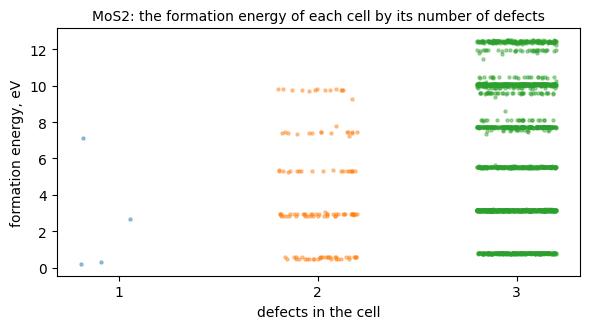

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.4))
rng = np.random.default_rng(0)
for k in (1, 2, 3):
    m = n_def == k
    ax.scatter(k + rng.uniform(-0.2, 0.2, m.sum()), y_mos2[m], s=5, alpha=0.4)
ax.set_xticks([1, 2, 3])
ax.set_xlabel("defects in the cell")
ax.set_ylabel("formation energy, eV")
ax.set_title("MoS2: the formation energy of each cell by its number of defects", fontsize=10)
plt.tight_layout()
plt.show()

Of the 2,000 MoS2 cells, 4 have one defect, 127 have two and 1,869 have three. The two lowest
energies belong to cells with one defect, and the mean energy rises from +2.55 eV with one defect
to +3.96 eV with two and +6.47 eV with three. So the number of defects decides most of the
energy, and the best cell is one of the four cells with a single defect. Four columns of counts,
fitted on 100 cells, explain 99 % of the variance of the rest (R² +0.993) and put the best cell
first. The whole-cell kernel explains 84 % and puts it near place 900.

An earlier reading of these numbers (plan item M11) said that a kernel model shrinks an isolated
best value toward the mean of the pool. The counts model is a kernel ridge model too, and it finds
the isolated cell. So that is not the reason.

The **difference fields** of the defect notebook describe only the changed sites: a cell is the
host plus a change, and the kernel compares the changes, averaged over the symmetry of the host.
That kernel counts the defects by construction and also sees where they are. In the table above it
finds the best MoS2 cell after a median of one call, as the counts do. The fields were not the
problem. The whole-cell kernel was the wrong field model for a pool in which only a few sites
change.

## A closed loop, with a calculator

In the pools above every value was known in advance. In a real study each call runs a
calculation. The cell builds a pool from a prototype: 8 of the 32 sites of an fcc copper cell
take Au, which allows 10,518,300 placements. A sample of 3,000 placements is reduced by symmetry,
and 400 distinct candidates are kept. Each candidate is relaxed by the EMT calculator of ASE, a
cheap potential for metals. Here the whole pool is also computed, once, so that the rank of what
the loop finds is exact; a real study cannot do that.

The composition is fixed, so only the arrangement varies. The cheap model is the **number of Au-Au
pairs** in each of the first three shells of neighbours. This is the classic description of an
alloy. The field model is the two-point autocorrelation of the cells.

In [8]:
t0 = time.time()
cl_pool, truth, per_call, cl_host = R.closed_pool()
print("%d candidates relaxed with EMT in %.0f s (%.2f s per call); energy %+.4f to %+.4f eV per atom" % (
    len(cl_pool), time.time() - t0, per_call, truth.min(), truth.max()))

from ase.calculators.emt import EMT
from cmfqsar import periodic

fs = periodic.inorganic_fieldset(elements=[], physchem=periodic.INORGANIC_FIELDS, charge_model="electronegativity", alpha=1.0)
cl_table = periodic.crystal_table([c.atoms for c in cl_pool], fs, [c.label for c in cl_pool])
spec = R.spec_of("two-point")
n_fields = cl_table.weights.shape[1]
K_cl_fields = P.pool_kernel(P.feature_matrix(cl_table.molecules, spec, n_fields), P.block_sizes(spec, n_fields))
K_cl_pairs = R.linear_kernel(R.neighbour_pair_columns(cl_pool, cl_host))
cl_starts = R.starts_for(len(cl_pool), R.CLOSED_START, R.CLOSED_SEEDS)
print()
print("a start set of %d, a budget of 30 calls, %d start sets; each call is a new EMT relaxation" % (R.CLOSED_START, len(cl_starts)))
for name, K, rule in (("random", K_cl_pairs, "random"), ("greedy on the fields", K_cl_fields, "greedy"),
                      ("greedy on the Au-Au pairs", K_cl_pairs, "greedy")):
    found = []
    for seed, start in enumerate(cl_starts):
        oracle = P.CalculatorOracle(EMT, relax=True)
        rec = P.design_loop(cl_pool, oracle, start=start, budget=30, kernel=K, rule=rule, beta=R.BETA,
                            lams=R.LAMS, maximise=False, seed=seed)
        found.append(int(np.sum(truth < rec["best"] - 1e-9)) + 1)
    print("   %-26s rank of the best found: %s; found the best of the pool in %d of %d runs" % (
        name, found, sum(1 for f in found if f == 1), len(found)))

400 candidates relaxed with EMT in 49 s (0.09 s per call); energy +0.0480 to +0.0805 eV per atom



a start set of 10, a budget of 30 calls, 5 start sets; each call is a new EMT relaxation


   random                     rank of the best found: [24, 4, 3, 1, 4]; found the best of the pool in 1 of 5 runs


   greedy on the fields       rank of the best found: [1, 1, 1, 1, 1]; found the best of the pool in 5 of 5 runs


   greedy on the Au-Au pairs  rank of the best found: [1, 1, 1, 1, 1]; found the best of the pool in 5 of 5 runs


The 400 relaxations take about 25 s here. With a budget of 30 calls, random choice finds the best
candidate of the pool in 1 of 5 runs. Greedy on the fields and greedy on the Au-Au pairs both find
it in 5 of 5. The stored stage, with a budget of 100 calls, gives the same: 5 of 5 for both
models, and the pairs model, fitted on its 10 start cells alone, puts the best candidate at place
2. A loop with a calculator works as a loop with a table does, and here the classic count of an
alloy does as well as the fields.

## What this shows and what it does not

**What it shows.**

- A prototype turns a design space into an index. The perovskite prototype allows 2,704
  candidates. Eight Au atoms on 32 sites allow 10,518,300 placements, and the symmetry reduction
  removes the duplicates (560 placements of three Au atoms on 16 sites are 10 structures).
- A design loop with a model beats random choice, on every pool where the model reads what
  changes.
- **The reference decides what the fields add.** A model on columns that need no field (the
  names of the elements, the counts of the defects, the Au-Au pairs) found the best candidates as
  fast as the fields or faster, on all four pools. On these pools the loop does not need the
  fields.
- Judge a model for a loop by where it puts the best candidate, not by its average accuracy. On
  MoS2 the whole-cell kernel has a rank correlation of +0.87 and puts the best cell near place
  900.
- Choose the field model that describes what changes. The difference fields of the defect
  notebook find the best MoS2 cell after one call; the whole-cell fields never reached the best
  1 %.

**What it does not show.**

- That fields never help a design loop. These pools are easy for counts: the energy of a
  perovskite depends mostly on its elements, and the energy of a defect cell mostly on the number
  of defects. Fields may add where the arrangement decides at a fixed composition and simple
  counts do not see it. In the closed loop of this size they did not add anything.
- A prospective study. Every pool here is retrospective, and the closed loop computes its whole
  pool. No new structure was proposed for a real question.
- Anything about the other rules with the cheap models. Only `greedy` and `ucb` were run with
  them; the stored stages hold four more rules for the fields.

The rule: before a design loop is credited to the fields, run it with the description a chemist
would write down without computing anything, and judge each model by where it puts the best
candidate.